In [1]:
import pandas as pd 
ames = pd.read_csv('../data/ames.csv')
ames.head()

,MS_SubClass,MS_Zoning,Lot_Frontage,Lot_Area,Street,Alley,Lot_Shape,Land_Contour,Utilities,Lot_Config,...,Fence,Misc_Feature,Misc_Val,Mo_Sold,Year_Sold,Sale_Type,Sale_Condition,Sale_Price,Longitude,Latitude
0,One_Story_1946_and_Newer_All_Styles,Residential_Low_Density,141,31770,Pave,No_Alley_Access,Slightly_Irregular,Lvl,AllPub,Corner,...,No_Fence,NaN,0,5,2010,WD,Normal,215000,-93.619754,42.054035
1,One_Story_1946_and_Newer_All_Styles,Residential_High_Density,80,11622,Pave,No_Alley_Access,Regular,Lvl,AllPub,Inside,...,Minimum_Privacy,NaN,0,6,2010,WD,Normal,105000,-93.619756,42.053014
2,One_Story_1946_and_Newer_All_Styles,Residential_Low_Density,81,14267,Pave,No_Alley_Access,Slightly_Irregular,Lvl,AllPub,Corner,...,No_Fence,Gar2,12500,6,2010,WD,Normal,172000,-93.619387,42.052659
3,One_Story_1946_and_Newer_All_Styles,Residential_Low_Density,93,11160,Pave,No_Alley_Access,Regular,Lvl,AllPub,Corner,...,No_Fence,NaN,0,4,2010,WD,Normal,244000,-93.617320,42.051245
4,Two_Story_1946_and_Newer,Residential_Low_Density,74,13830,Pave,No_Alley_Access,Slightly_Irregular,Lvl,AllPub,Inside,...,Minimum_Privacy,NaN,0,3,2010,WD,Normal,189900,-93.638933,42.060899


## Checking the Ames data for multicollinearity



In [4]:
# numeric predictors only (Sale_Price is the target, so leave it out)
num = ames.select_dtypes('number').drop(columns='Sale_Price').dropna()
num.shape

(2930, 34)

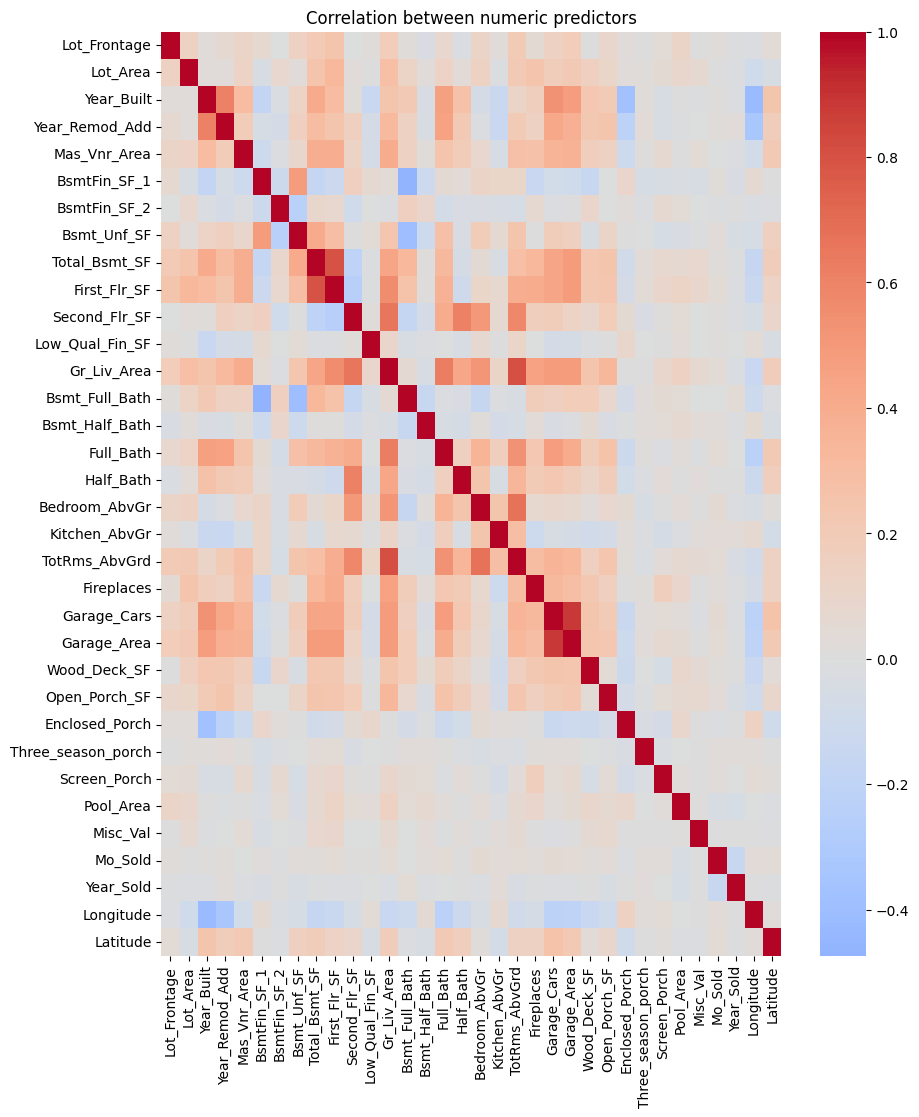

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

corr = num.corr()
plt.figure(figsize=(10, 12))
sns.heatmap(corr, cmap='coolwarm', center=0)
plt.title('Correlation between numeric predictors')
plt.show()

In [14]:
import numpy as np

# keep only the upper triangle so each pair appears once, then list pairs with |r| > 0.7
upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
pairs = upper.stack().loc[lambda s: s.abs() > 0.4].sort_values(key=abs, ascending=False)
pairs

Garage_Cars     Garage_Area       0.889866
Gr_Liv_Area     TotRms_AbvGrd     0.807772
Total_Bsmt_SF   First_Flr_SF      0.800429
Bedroom_AbvGr   TotRms_AbvGrd     0.672647
Second_Flr_SF   Gr_Liv_Area       0.655251
Gr_Liv_Area     Full_Bath         0.630321
Year_Built      Year_Remod_Add    0.612095
Second_Flr_SF   Half_Bath         0.611634
                TotRms_AbvGrd     0.585214
First_Flr_SF    Gr_Liv_Area       0.562166
Year_Built      Garage_Cars       0.537982
Full_Bath       TotRms_AbvGrd     0.528599
Gr_Liv_Area     Bedroom_AbvGr     0.516808
Second_Flr_SF   Bedroom_AbvGr     0.504651
First_Flr_SF    Garage_Area       0.491208
BsmtFin_SF_1    Bsmt_Unf_SF       0.488014
Gr_Liv_Area     Garage_Cars       0.487829
Total_Bsmt_SF   Garage_Area       0.485608
Gr_Liv_Area     Garage_Area       0.483971
Year_Built      Garage_Area       0.480726
Full_Bath       Garage_Cars       0.477070
BsmtFin_SF_1    Bsmt_Full_Bath   -0.473424
Year_Built      Full_Bath         0.469406
Year_Remod_

## I will use `Year_Built`, `Central_Air` for this example.

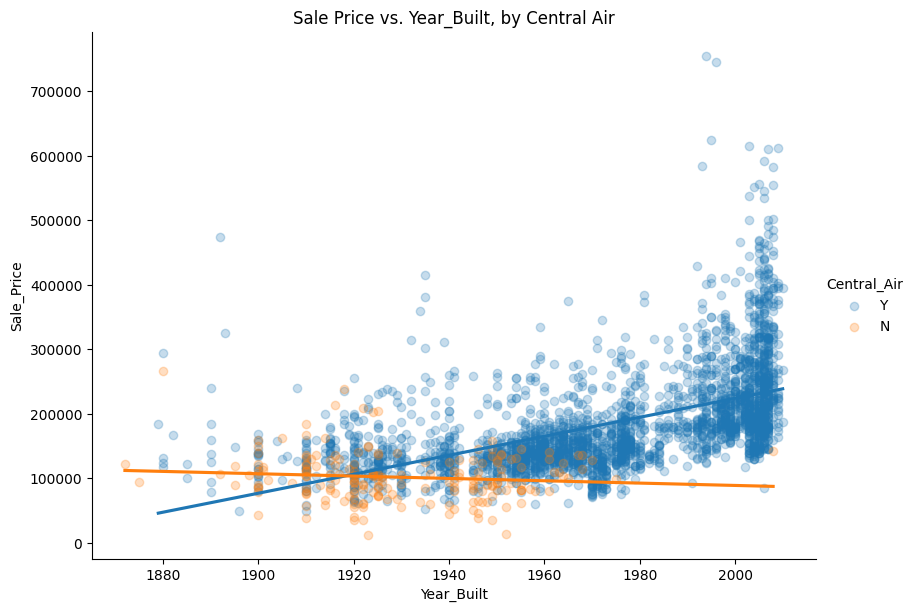

In [31]:
sns.lmplot(
    data=ames, x="Year_Built", y="Sale_Price", hue="Central_Air",
    height=6, aspect=1.4, scatter_kws={"alpha": 0.25}, ci=None,
)
plt.title("Sale Price vs. Year_Built, by Central Air")
plt.show()

## The lines aren't parrallel, so we see there exists an interaction.

In [20]:
ames["Central_Air"].value_counts()

Central_Air
Y    2734
N     196
Name: count, dtype: int64

In [21]:

cols = ["Bldg_Type", "Gr_Liv_Area", "Sale_Price"]
ames[cols].head()

,Bldg_Type,Gr_Liv_Area,Sale_Price
0,OneFam,1656,215000
1,OneFam,896,105000
2,OneFam,1329,172000
3,OneFam,2110,244000
4,OneFam,1629,189900


## Screening the interaction

In [23]:
#copying all of your imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import statsmodels.formula.api as smf
import statsmodels.api as sm

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import cross_val_score

## Nested model comparison

In [24]:
main_effects_fit = smf.ols("Sale_Price ~ Year_Built + C(Central_Air)", data=ames).fit()
interaction_fit = smf.ols("Sale_Price ~ Year_Built * C(Central_Air)", data=ames).fit()

print("Main effects only: R-squared =", round(main_effects_fit.rsquared, 4))
print("With interaction:  R-squared =", round(interaction_fit.rsquared, 4))
print()

anova_table = sm.stats.anova_lm(main_effects_fit, interaction_fit)
anova_table

Main effects only: R-squared = 0.3156
With interaction:  R-squared = 0.3277



,df_resid,ssr,df_diff,ss_diff,F,Pr(>F)
0,2927.0,1.279312e+13,0.0,NaN,NaN,NaN
1,2926.0,1.256760e+13,1.0,2.255176e+11,52.505195,5.463711e-13


Small Pvalue in the interaction fit, not as small as in the notebook.

## Out of fold RMSE cross validated comparison

In [25]:
X = ames[["Year_Built", "Central_Air"]]
y = ames["Sale_Price"]

encode_central_air = ColumnTransformer([
    ("central_air", OneHotEncoder(drop="first"), ["Central_Air"]),
], remainder="passthrough")

main_effects_pipe = Pipeline([
    ("encode", encode_central_air),
    ("model", LinearRegression()),
])

interaction_pipe = Pipeline([
    ("encode", encode_central_air),
    ("interact", PolynomialFeatures(interaction_only=True, include_bias=False)),
    ("model", LinearRegression()),
])

main_effects_rmse = -cross_val_score(
    main_effects_pipe, X, y, cv=5, scoring="neg_root_mean_squared_error"
)
interaction_rmse = -cross_val_score(
    interaction_pipe, X, y, cv=5, scoring="neg_root_mean_squared_error"
)

print("Main effects only, CV RMSE: {:,.0f}  (+/- {:,.0f})".format(
    main_effects_rmse.mean(), main_effects_rmse.std()))
print("With interaction,  CV RMSE: {:,.0f}  (+/- {:,.0f})".format(
    interaction_rmse.mean(), interaction_rmse.std()))

Main effects only, CV RMSE: 66,085  (+/- 4,493)
With interaction,  CV RMSE: 65,491  (+/- 4,598)


In [27]:
pd.DataFrame({
    "main_effects_rmse": main_effects_rmse,
    "interaction_rmse": interaction_rmse,
    "improvement": main_effects_rmse - interaction_rmse,
}, index=[f"fold {i+1}" for i in range(5)]).round(0)

,main_effects_rmse,interaction_rmse,improvement
fold 1,71950.0,71429.0,521.0
fold 2,59595.0,58676.0,919.0
fold 3,63858.0,63192.0,667.0
fold 4,70286.0,69696.0,590.0
fold 5,64736.0,64465.0,271.0


A lower RMSE for the interaction model suggests a present, yet small interaction present.

## Fitting the interaction model on the full training data

Cross-validation fits the model several times on parts of the data, only to estimate how well it predicts. The final interaction model is fit once on all of the training data. Its coefficients show how the effect of `Year_Built` on price changes when a house has central air.

In [30]:
from sklearn.metrics import root_mean_squared_error

# full training data: every predictor except the target
X_full = ames.drop(columns="Sale_Price").copy()
y_full = ames["Sale_Price"]

# add only the interaction we tested: Year_Built times central air (1 = Yes, 0 = No)
X_full["YearBuilt_x_CentralAir"] = X_full["Year_Built"] * (X_full["Central_Air"] == "Y").astype(int)

# one-hot encode every text column so LinearRegression gets numbers only; numeric columns pass through
cat_cols = X_full.select_dtypes(include="object").columns
encode_all = ColumnTransformer([
    ("categorical", OneHotEncoder(drop="first", handle_unknown="ignore"), cat_cols),
], remainder="passthrough")

full_interaction_pipe = Pipeline([
    ("encode", encode_all),
    ("model", LinearRegression()),
])

# fit once on all of the training data
full_interaction_pipe.fit(X_full, y_full)

train_rmse = root_mean_squared_error(y_full, full_interaction_pipe.predict(X_full))
print("Interaction model on all predictors, RMSE on the training data: {:,.0f}".format(train_rmse))
print("Number of columns after encoding:", len(full_interaction_pipe.named_steps["encode"].get_feature_names_out()))

# coefficients for year built and the interaction column
coefs = pd.Series(
    full_interaction_pipe.named_steps["model"].coef_,
    index=full_interaction_pipe.named_steps["encode"].get_feature_names_out(),
)
coefs[["remainder__Year_Built", "remainder__YearBuilt_x_CentralAir"]]

Interaction model on all predictors, RMSE on the training data: 23,807
Number of columns after encoding: 307


remainder__Year_Built                313.814521
remainder__YearBuilt_x_CentralAir     -1.253205
dtype: float64

## Thoughts on performance
With only two predictors, there is a slight improvement with the interaction model. This effect disappears when training on the full data, likely because only
196/2734 (7%) of the houses are missing central air and other predictors have greater influence. 


## Part 2: SMOTE on covertype 

In [33]:
covertype = pd.read_csv('../data/covtype.csv')
covertype

,Elevation,Aspect,Slope,Horizontal_Distance_To_Hydrology,Vertical_Distance_To_Hydrology,Horizontal_Distance_To_Roadways,Hillshade_9am,Hillshade_Noon,Hillshade_3pm,Horizontal_Distance_To_Fire_Points,...,Soil_Type32,Soil_Type33,Soil_Type34,Soil_Type35,Soil_Type36,Soil_Type37,Soil_Type38,Soil_Type39,Soil_Type40,Cover_Type
0,2596,51,3,258,0,510,221,232,148,6279,...,0,0,0,0,0,0,0,0,0,5
1,2590,56,2,212,-6,390,220,235,151,6225,...,0,0,0,0,0,0,0,0,0,5
2,2804,139,9,268,65,3180,234,238,135,6121,...,0,0,0,0,0,0,0,0,0,2
3,2785,155,18,242,118,3090,238,238,122,6211,...,0,0,0,0,0,0,0,0,0,2
4,2595,45,2,153,-1,391,220,234,150,6172,...,0,0,0,0,0,0,0,0,0,5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
581007,2396,153,20,85,17,108,240,237,118,837,...,0,0,0,0,0,0,0,0,0,3
581008,2391,152,19,67,12,95,240,237,119,845,...,0,0,0,0,0,0,0,0,0,3
581009,2386,159,17,60,7,90,236,241,130,854,...,0,0,0,0,0,0,0,0,0,3
581010,2384,170,15,60,5,90,230,245,143,864,...,0,0,0,0,0,0,0,0,0,3


## Synthetic Minority Over-sampling Technique:
addresses class imbalance. generates synthetic examples for the minority class rather than duplicating them. The algorithm uses knn and linear interpolation to create accurate samples. 
SMOTE raises the counts of each class to the largest one, significantly increasing training time. 

## Why use imblearn?
Imbalanced learn: It prevents data leakage by applying preprocessing steps inside each cv fold, which in our case is by creating synthetic training samples within CV instead of outside using SMOTE. 

In [34]:
from sklearn.model_selection import train_test_split, cross_val_score
X = covertype.drop(columns="Cover_Type")
y = covertype["Cover_Type"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [40]:
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
from sklearn.ensemble import RandomForestClassifier
pipeline = ImbPipeline(steps=[
    ('smote', SMOTE(random_state=42)),
    ('classifier', RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1))
])

In [41]:
from sklearn.metrics import classification_report
pipeline.fit(X_train, y_train)
y_pred = pipeline.predict(X_test)
print("Classification Report:")
print(classification_report(y_test, y_pred))

# Optional: Evaluate robustly using cross-validation
cv_scores = cross_val_score(pipeline, X_train, y_train, cv=5, scoring='f1_macro')
print(f"Cross-Validation F1-Macro Mean: {cv_scores.mean():.4f}")

Classification Report:
              precision    recall  f1-score   support

           1       0.96      0.95      0.96     42368
           2       0.96      0.96      0.96     56661
           3       0.94      0.97      0.95      7151
           4       0.89      0.90      0.89       549
           5       0.88      0.93      0.90      1899
           6       0.91      0.93      0.92      3473
           7       0.95      0.98      0.97      4102

    accuracy                           0.96    116203
   macro avg       0.93      0.94      0.94    116203
weighted avg       0.96      0.96      0.96    116203

Cross-Validation F1-Macro Mean: 0.9320


## Baseline that skips SMOTE

In [ ]:
from sklearn.metrics import f1_score

models = {
      "No resampling (baseline)": RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1),
      "class_weight='balanced'":  RandomForestClassifier(n_estimators=100, class_weight='balanced', random_state=42,
  n_jobs=-1)

  }



In [46]:
from sklearn.metrics import classification_report

for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    print(f"===== {name} =====")
    print("Classification Report:")
    print(classification_report(y_test, y_pred))
    print(f"Test F1-Macro: {f1_score(y_test, y_pred, average='macro'):.4f}")

    # Optional: Evaluate robustly using cross-validation
    cv_scores = cross_val_score(model, X_train, y_train, cv=5, scoring='f1_macro')
    print(f"Cross-Validation F1-Macro Mean: {cv_scores.mean():.4f}")
    print()

===== No resampling (baseline) =====
Classification Report:
              precision    recall  f1-score   support

           1       0.96      0.94      0.95     42368
           2       0.95      0.97      0.96     56661
           3       0.94      0.96      0.95      7151
           4       0.92      0.86      0.89       549
           5       0.95      0.77      0.85      1899
           6       0.93      0.89      0.91      3473
           7       0.97      0.95      0.96      4102

    accuracy                           0.95    116203
   macro avg       0.95      0.91      0.92    116203
weighted avg       0.95      0.95      0.95    116203

Test F1-Macro: 0.9241
Cross-Validation F1-Macro Mean: 0.9169

===== class_weight='balanced' =====
Classification Report:
              precision    recall  f1-score   support

           1       0.97      0.94      0.95     42368
           2       0.95      0.97      0.96     56661
           3       0.94      0.96      0.95      7151
     

SMOTE helped the F1-Macro Mean by about 0.02 points. 

## Predict probability and SMOTE

In [47]:
from sklearn.metrics import log_loss

baseline = models["No resampling (baseline)"]
compare = pd.DataFrame({
      "actual share in test": y_test.value_counts(normalize=True).sort_index(),
      "baseline mean prob":   baseline.predict_proba(X_test).mean(axis=0),
      "SMOTE mean prob":      pipeline.predict_proba(X_test).mean(axis=0),
  }, index=pipeline.classes_).round(4)
print(compare)

   actual share in test  baseline mean prob  SMOTE mean prob
1                0.3646              0.3643           0.3680
2                0.4876              0.4883           0.4706
3                0.0615              0.0617           0.0636
4                0.0047              0.0046           0.0051
5                0.0163              0.0163           0.0214
6                0.0299              0.0296           0.0329
7                0.0353              0.0352           0.0383


SMOTE actually did affect the predicted probabilities of cover types. If you compare the number in each category to the scores vs baseline, you will notice the categories with the most numbers had lower probabilities (1,2) while the smaller categories have their probabilities inflated, likely due to how SMOTE deals with imbalanced data.

## Magnitude of cover types

In [49]:
counts = covertype["Cover_Type"].value_counts().sort_index()
pd.DataFrame({
      "count": counts,
      "percent": (counts / counts.sum() * 100).round(2),
  })

,count,percent
Cover_Type,,
1,211840,36.46
2,283301,48.76
3,35754,6.15
4,2747,0.47
5,9493,1.63
6,17367,2.99
7,20510,3.53
